# 2. Основной анализ

Сравниваем группы по целевой метрике (`retention_7`), вторичной (`retention_1`) и барьерной (`sum_gamerounds`). Разность везде считается как тест − контроль, то есть «ворота на 40-м» минус «ворота на 30-м». Анализ по всем распределённым игрокам (intention-to-treat), без удаления выбросов — как решили в ноутбуке 1.

**План:** z-тест и bootstrap для удержания → байесовская оценка и перевод эффекта в игроков → раунды устойчивыми методами → поправка на множественные сравнения → поправка на дисбаланс групп до ворот → итог.

In [1]:
import sys
sys.path[:0] = ["src", "../src"]  # notebooks/src — стиль графиков, src — библиотека abtest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from abtest import stats as S, bayes
from _style import (setup, commas, percent, num, pct, pp, pval, thousands,
                    COLORS, LABELS, METRIC, CONTROL, TEST, NEUTRAL, MUTED, TEXT)
setup()

df = pd.read_csv("../data/cookie_cats.csv")
A, B = df[df.version == "gate_30"], df[df.version == "gate_40"]
nA, nB = len(A), len(B)
GATE_FREE = 29  # меньше 29 раундов — до ворот точно не дошёл (см. ноутбук 1)

## 2.1. Удержание: z-тест для двух долей

Метрика бинарная (вернулся / не вернулся), выборки большие — подходит z-тест для разности долей. p-value считаем с объединённой оценкой дисперсии (так формулируется нулевая гипотеза «доли равны»), а доверительный интервал разности — с раздельной.

In [2]:
z = {m: S.two_proportion_test(A[m].sum(), nA, B[m].sum(), nB) for m in ["retention_7", "retention_1"]}
pd.DataFrame([{"метрика": METRIC[m], "контроль": pct(r["p_a"], 2), "тест": pct(r["p_b"], 2),
               "разница, п.п.": pp(r["diff"]), "95% ДИ, п.п.": f"[{pp(r['ci'][0])}; {pp(r['ci'][1])}]",
               "отн. изменение": num(r["rel_lift"] * 100, 1, True) + "%", "p-value": pval(r["p_value"])}
              for m, r in z.items()]).set_index("метрика")

,контроль,тест,"разница, п.п.","95% ДИ, п.п.",отн. изменение,p-value
метрика,,,,,,
удержание на 7-й день,"19,02%","18,20%","−0,82","[−1,33; −0,31]","−4,3%","0,0016"
удержание на 1-й день,"44,82%","44,23%","−0,59","[−1,24; +0,06]","−1,3%","0,074"


**Целевая метрика.** 7-дневное удержание в тесте ниже на 0,82 п.п. (19,02% → 18,20%, относительно −4,3%), p ≈ 0,0016. Доверительный интервал [−1,33; −0,31] п.п. целиком ниже нуля: перенос ворот на 40-й уровень ухудшает удержание через неделю.

**Вторичная метрика.** 1-дневное удержание тоже ниже (−0,59 п.п.), но p ≈ 0,074: на уровне 0,05 различие не доказано.

## 2.2. Та же разница через bootstrap

Проверка без предположения о нормальности. Для бинарной метрики ресэмплинг выборки из n игроков с долей p эквивалентен Binomial(n, p)/n, поэтому 10 000 повторов считаются мгновенно.

Bootstrap 95% ДИ разницы удержания на 7-й день: [−1,32; −0,31] п.п.
Доля повторов, где тест хуже контроля: 99,92%


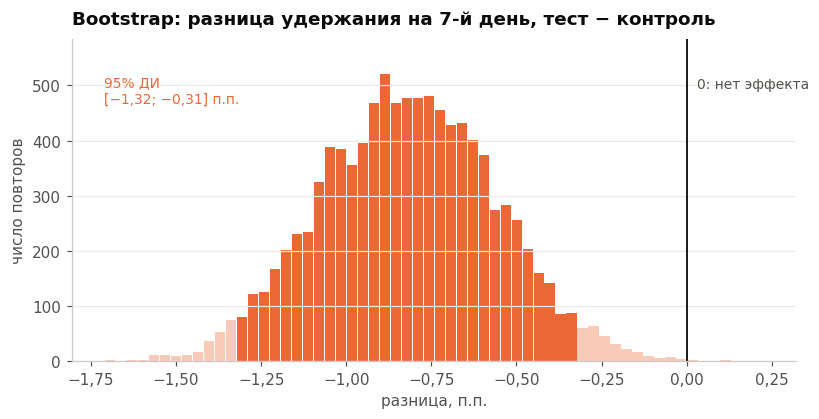

In [3]:
boot = S.bootstrap_proportion_diff(A.retention_7.sum(), nA, B.retention_7.sum(), nB, n_boot=10_000)
print(f"Bootstrap 95% ДИ разницы удержания на 7-й день: [{pp(boot['ci'][0])}; {pp(boot['ci'][1])}] п.п.")
print(f"Доля повторов, где тест хуже контроля: {pct(boot['p_b_less'], 2)}")

d = boot["samples"] * 100
lo, hi = boot["ci"][0] * 100, boot["ci"][1] * 100
fig, ax = plt.subplots(figsize=(8.5, 3.8))
bins = np.linspace(d.min(), max(d.max(), 0.15), 61)
cnt, edges = np.histogram(d, bins)
mid = (edges[:-1] + edges[1:]) / 2
inside = (mid >= lo) & (mid <= hi)
ax.bar(mid[inside], cnt[inside], width=np.diff(edges)[0] * 0.92, color=TEST, label="внутри 95% ДИ")
ax.bar(mid[~inside], cnt[~inside], width=np.diff(edges)[0] * 0.92, color=TEST, alpha=0.35, label="за пределами")
ax.axvline(0, color=TEXT, lw=1.2)
ax.text(0.03, cnt.max() * 0.95, "0: нет эффекта", fontsize=9, color=MUTED)
ax.text(edges[0], cnt.max() * 0.9, f"95% ДИ\n[{num(lo)}; {num(hi)}] п.п.", ha="left", fontsize=9, color=TEST)
ax.set_ylim(0, cnt.max() * 1.12)
ax.grid(axis="x", visible=False)
commas(ax)
ax.set(title="Bootstrap: разница удержания на 7-й день, тест − контроль", xlabel="разница, п.п.", ylabel="число повторов")

Bootstrap даёт тот же интервал, что и z-тест: в 99,9% повторов тест хуже контроля.

## 2.3. Байесовский взгляд: вероятность и цена ошибки

p-value отвечает на вопрос «насколько странны такие данные, если эффекта нет». Продуктовой команде обычно нужно другое: какова вероятность, что тест хуже контроля, и сколько мы потеряем, если ошибёмся с выбором. Оба ответа даёт байесовская модель.

Для каждой группы доля вернувшихся игроков p получает априорное распределение Beta(a, b). После x вернувшихся из n апостериорное распределение равно Beta(a + x, b + n − x), его можно выписать точно. Из двух апостериорных берём по 200 000 случайных значений и по их разнице считаем:

- P(тест хуже) — долю пар, где p теста меньше p контроля;
- интервал, в котором разница лежит с вероятностью 95% (равнохвостый, по 2,5% с каждой стороны);
- ожидаемые потери при выборе варианта, E[max(p_другого − p_выбранного, 0)]: на сколько п.п. удержания мы в среднем проигрываем, если выбранный вариант на самом деле хуже. Если он лучше, потери нулевые. Обычное правило: выбрать вариант, когда его ожидаемые потери ниже порога, согласованного с командой;
- вероятность того, что тест хуже на практически заметную величину. Порог 0,25 п.п. здесь условный: это допущение о том, какое изменение удержания продукт считает несущественным.

Априорное распределение по умолчанию равномерное, Beta(1, 1): любое значение удержания от 0 до 100% одинаково правдоподобно.

In [4]:
ROPE = 0.0025  # 0,25 п.п.
bay = {m: bayes.compare_proportions(A[m].sum(), nA, B[m].sum(), nB, threshold=ROPE)
       for m in ["retention_7", "retention_1"]}


pd.DataFrame([{
    "метрика": METRIC[m],
    "контроль": num(r["p_a"] * 100) + "%",
    "тест": num(r["p_b"] * 100) + "%",
    "разница, п.п.": pp(r["diff"]),
    "95% интервал, п.п.": f"[{pp(r['ci'][0])}; {pp(r['ci'][1])}]",
    "отн. изменение": f"{pp(r['rel_lift'], 1)}% [{pp(r['rel_ci'][0], 1)}; {pp(r['rel_ci'][1], 1)}]",
    "P(тест хуже)": num(r["prob_b_less"] * 100, 1) + "%",
    f"P(тест хуже > {num(ROPE * 100)} п.п.)": num(r["prob_below"] * 100, 1) + "%",
    "потери при выборе контроля, п.п.": pp(r["loss_choose_a"], 3, False),
    "потери при выборе теста, п.п.": pp(r["loss_choose_b"], 3, False),
} for m, r in bay.items()]).set_index("метрика").T

метрика,удержание на 7-й день,удержание на 1-й день
контроль,"19,02%","44,82%"
тест,"18,20%","44,23%"
"разница, п.п.","−0,82","−0,59"
"95% интервал, п.п.","[−1,33; −0,31]","[−1,24; +0,06]"
отн. изменение,"−4,3% [−6,9; −1,7]","−1,3% [−2,7; +0,1]"
P(тест хуже),"99,9%","96,3%"
"P(тест хуже > 0,25 п.п.)","98,6%","85,0%"
"потери при выборе контроля, п.п.","0,000","0,005"
"потери при выборе теста, п.п.","0,821","0,597"


По 7-дневному удержанию тест хуже контроля с вероятностью 99,9%, а хуже больше чем на 0,25 п.п. — с вероятностью 98,6%. Интервал разницы [−1,33; −0,31] п.п. почти совпадает с доверительным интервалом z-теста: при таких выборках апостериорное распределение близко к нормальному с тем же центром и разбросом. Ожидаемые потери несимметричны: оставив контроль, мы в среднем теряем практически ноль (около одного игрока на миллион установок), а выбрав тест — 0,82 п.п.

По 1-дневному удержанию картина та же по направлению, но менее определённая: P(тест хуже) = 96,3%, интервал [−1,24; +0,06] п.п. включает ноль. Это не противоречит p = 0,074 из раздела 2.1: при равномерном априорном P(тест хуже) примерно равна 1 − p/2.

**Зависит ли вывод от априорного распределения?** Сравним равномерное с двумя информативными, центрированными на 19% (типичное удержание на 7-й день): «слабым», которое стоит 100 игроков, и в десять раз более сильным.

In [5]:
priors = {"равномерное Beta(1, 1)": bayes.UNIFORM,
          "Beta(19, 81): 19%, вес 100 игроков": bayes.prior_from_mean(0.19, 100),
          "Beta(190, 810): 19%, вес 1000 игроков": bayes.prior_from_mean(0.19, 1000)}
x7a, x7b = A.retention_7.sum(), B.retention_7.sum()
sens = {name: bayes.compare_proportions(x7a, nA, x7b, nB, prior=pr) for name, pr in priors.items()}
pd.DataFrame([{"априорное": name, "разница, п.п.": pp(r["diff"], 3),
               "95% интервал, п.п.": f"[{pp(r['ci'][0], 3)}; {pp(r['ci'][1], 3)}]",
               "P(тест хуже)": num(r["prob_b_less"] * 100, 2) + "%",
               "потери при выборе теста, п.п.": pp(r["loss_choose_b"], 3, False)}
              for name, r in sens.items()]).set_index("априорное")

,"разница, п.п.","95% интервал, п.п.",P(тест хуже),"потери при выборе теста, п.п."
априорное,,,,
"равномерное Beta(1, 1)","−0,821","[−1,329; −0,311]","99,92%","0,821"
"Beta(19, 81): 19%, вес 100 игроков","−0,819","[−1,327; −0,310]","99,92%","0,819"
"Beta(190, 810): 19%, вес 1000 игроков","−0,803","[−1,306; −0,299]","99,91%","0,803"


Априорное в 100 игроков против 44–45 тысяч наблюдений в каждой группе сдвигает разницу на 0,002 п.п. Даже вес в 1000 игроков, который тянет обе группы к 19%, сдвигает её на 0,02 п.п., а P(тест хуже) остаётся 99,9%. Выбор априорного здесь дело формальности: данных столько, что они полностью его перевешивают.

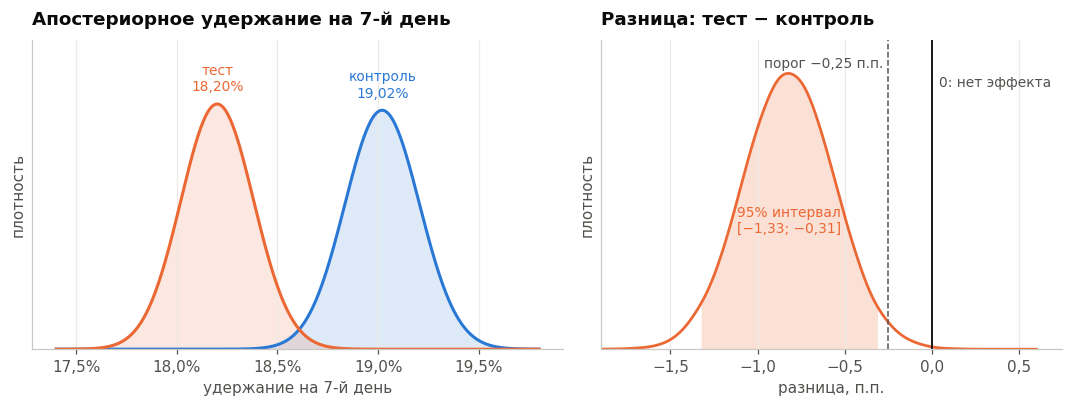

In [6]:
r7 = bay["retention_7"]
postA, postB = bayes.posterior(x7a, nA), bayes.posterior(x7b, nB)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})

grid = np.linspace(0.174, 0.198, 600)
for post, color, label in [(postA, CONTROL, "контроль"), (postB, TEST, "тест")]:
    dens = post.pdf(grid)
    ax1.plot(grid, dens, color=color)
    ax1.fill_between(grid, dens, color=color, alpha=0.15, lw=0)
    ax1.text(post.mean(), dens.max() * 1.04, f"{label}\n{num(post.mean() * 100)}%", ha="center", va="bottom",
             fontsize=9, color=color)
percent(ax1, "x", 1)
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.2)
ax1.set_yticks([])
ax1.set(title="Апостериорное удержание на 7-й день", xlabel="удержание на 7-й день", ylabel="плотность")

d = r7["samples"] * 100
mid = np.linspace(-1.9, 0.6, 500)
hist = stats.gaussian_kde(d[::4], bw_method=0.2)(mid)  # сглаженная плотность по 50 000 из 200 000 значений
ax2.plot(mid, hist, color=TEST, lw=1.8)
inside = (mid >= r7["ci"][0] * 100) & (mid <= r7["ci"][1] * 100)
ax2.fill_between(mid, hist, where=inside, color=TEST, alpha=0.2, lw=0)
ax2.axvline(0, color="#0b0b0b", lw=1.2)
ax2.axvline(-ROPE * 100, color=MUTED, ls="--", lw=1)
top = hist.max()
ax2.text(0.04, top * 0.95, "0: нет эффекта", fontsize=9, color=MUTED)
ax2.text(-ROPE * 100 - 0.03, top * 1.02, f"порог −{num(ROPE * 100)} п.п.", ha="right", fontsize=9, color=MUTED)
ax2.text(r7["diff"] * 100, top * 0.42,
         f"95% интервал\n[{pp(r7['ci'][0])}; {pp(r7['ci'][1])}]", ha="center", fontsize=9, color=TEST)
ax2.set_xlim(-1.9, 0.75)
ax2.set_ylim(0, top * 1.12)
ax2.set_yticks([])
commas(ax2)
ax2.set(title="Разница: тест − контроль", xlabel="разница, п.п.", ylabel="плотность")
fig.tight_layout()

Распределения удержания почти не перекрываются, а распределение разницы практически целиком лежит левее нуля и почти целиком левее порога −0,25 п.п.

**Что это значит в игроках.** Разницу долей удобно перевести в число игроков на 100 000 установок: столько удержанных на 7-й (и 1-й) день игроков мы теряли бы, перенеся ворота.

In [7]:
for m in ["retention_7", "retention_1"]:
    k = bayes.per_installs(bay[m]["diff"], bay[m]["ci"])
    print(f"{METRIC[m]}: удержанных игроков на 100 000 установок {thousands(k['players'], True)}, "
          f"95% интервал [{thousands(k['ci'][0], True)}; {thousands(k['ci'][1], True)}]")

удержание на 7-й день: удержанных игроков на 100 000 установок −821, 95% интервал [−1 329; −311]
удержание на 1-й день: удержанных игроков на 100 000 установок −592, 95% интервал [−1 238; +58]


На каждые 100 000 установок перенос ворот стоил бы около 820 игроков, вернувшихся через неделю (с вероятностью 95% от 311 до 1 329). Для 1-го дня оценка около 590 игроков, но интервал [−1 238; +58] включает ноль.

Байесовский анализ приводит к тому же решению, что и z-тест: с вероятностью 99,9% ворота на 40-м уровне снижают 7-дневное удержание, и почти наверняка больше чем на 0,25 п.п. Ожидаемая цена выбора теста (0,82 п.п.) на четыре порядка выше цены сохранения контроля, поэтому оставляем ворота на 30-м уровне. Вывод не зависит от разумного выбора априорного распределения.

Все оценки этого раздела сделаны по прямому сравнению групп. В разделе 2.6 видно, что после поправки на дисбаланс групп до ворот эффект становится меньше, и в игроках тоже.

## 2.4. Раунды: метрика с тяжёлым хвостом

При n ≈ 45 тыс. t-тест на средних формально работает (центральная предельная теорема), но среднее здесь определяется хвостом: один игрок с 49 854 раундами сдвигает среднее контроля почти на 1,1 раунда. Поэтому смотрим на метрику с нескольких сторон.

In [8]:
ra, rb = A.sum_gamerounds.values, B.sum_gamerounds.values
cap = np.percentile(df.sum_gamerounds, 99.9)
mw = S.mann_whitney(ra, rb)
logt = S.welch_log_ttest(ra, rb)
b_med = S.bootstrap_stat_diff(ra, rb, np.median, n_boot=2000, seed=1)
b_mean = S.bootstrap_stat_diff(ra, rb, np.mean, n_boot=2000, seed=2)
b_mean_w = S.bootstrap_stat_diff(np.minimum(ra, cap), np.minimum(rb, cap), np.mean, n_boot=2000, seed=3)

ci = lambda r, k=2: f"[{num(r['ci'][0], k, True)}; {num(r['ci'][1], k, True)}]"
pd.DataFrame([
    {"метод": "тест Манна — Уитни", "что оценивает": "P(тест > контроль) + ½·P(равны)",
     "оценка": num(mw["prob_superiority"], 3), "95% ДИ": "—", "p-value": pval(mw["p_value"])},
    {"метод": "t-тест Уэлча на log(1 + раунды)", "что оценивает": "отношение геометрических средних (1 + раунды)",
     "оценка": "×" + num(logt["ratio_geo"], 3), "95% ДИ": f"[×{num(logt['ratio_ci'][0], 3)}; ×{num(logt['ratio_ci'][1], 3)}]",
     "p-value": pval(logt["p_value"])},
    {"метод": "bootstrap медианы", "что оценивает": "разница медиан, раундов",
     "оценка": num(b_med["diff"], 0, True), "95% ДИ": ci(b_med, 0), "p-value": "—"},
    {"метод": "bootstrap среднего (все игроки)", "что оценивает": "разница средних, раундов",
     "оценка": num(b_mean["diff"], 2, True), "95% ДИ": ci(b_mean), "p-value": "—"},
    {"метод": f"bootstrap среднего (винзоризация на {cap:.0f})", "что оценивает": "разница средних, раундов",
     "оценка": num(b_mean_w["diff"], 2, True), "95% ДИ": ci(b_mean_w), "p-value": "—"},
]).set_index("метод")

,что оценивает,оценка,95% ДИ,p-value
метод,,,,
тест Манна — Уитни,P(тест > контроль) + ½·P(равны),"0,496",—,"0,0502"
t-тест Уэлча на log(1 + раунды),отношение геометрических средних (1 + раунды),"×0,982","[×0,963; ×1,001]","0,070"
bootstrap медианы,"разница медиан, раундов",−1,[−1; +0],—
bootstrap среднего (все игроки),"разница средних, раундов","−1,16","[−4,08; +1,03]",—
bootstrap среднего (винзоризация на 1074),"разница средних, раундов","−0,10","[−1,30; +1,15]",—


Тест Манна — Уитни часто описывают как «сравнение медиан», но проверяет он другое: равна ли 50% вероятность того, что случайный игрок из теста сыграл больше случайного игрока из контроля (ничьи считаются пополам). Здесь эта вероятность 0,496, практически половина. Bootstrap медианы на целых числах груб: медиана может сдвинуться только на целый раунд, поэтому интервал [−1; 0] стоит читать как «медиана в тесте меньше не больше чем на раунд».

Все методы показывают одно: вовлечённость в тесте если и ниже, то совсем немного (−1 раунд по медиане, «типичный» игрок играет примерно на 2% меньше), и ни один интервал уверенно не отделён от нуля. После винзоризации разница средних почти исчезает: разброс среднего «со всеми» объясняется хвостом.

Формально проверить барьерную метрику на «непросадку» нельзя: допустимый порог падения заранее не задавали. Интервал для «типичного» игрока — от −3,7% до +0,1%. Если команда считает допустимым падение активности до 5%, барьер выдержан.

## 2.5. Поправка на множественные сравнения

Целевая метрика одна и проверяется на α = 0,05 без поправки. Вторичная и барьерная — семейство из двух проверок, к нему применяем Холма (контролирует вероятность хотя бы одной ложной находки и мощнее Бонферрони).

In [9]:
fam = S.holm([z["retention_1"]["p_value"], mw["p_value"]])
pd.DataFrame([{"метрика": name, "p-value": pval(f["p"]), "p-value по Холму": pval(f["p_holm"]),
               "значимо при α = 0,05": "да" if f["reject"] else "нет"}
              for name, f in zip(["удержание на 1-й день (z-тест)", "раунды (Манна — Уитни)"], fam)]).set_index("метрика")

,p-value,p-value по Холму,"значимо при α = 0,05"
метрика,,,
удержание на 1-й день (z-тест),"0,074","0,100",нет
раунды (Манна — Уитни),"0,0502","0,100",нет


После поправки ни вторичная, ни барьерная метрика значимых различий не показывают.

## 2.6. Поправка на дисбаланс групп до ворот

В ноутбуке 1 нашлось, что в тесте на 0,73 п.п. больше игроков, сыгравших меньше 29 раундов. Эти игроки ни одних ворот не видели: на каждый уровень нужен хотя бы один раунд, а ворота стоят на 30-м уровне. Удержание у них совсем другое, чем у остальных, поэтому даже небольшой перекос в их доле сдвигает прямое сравнение групп.

Ключевое наблюдение: величина min(раунды, 29) не зависит от того, где стоят ворота. Пока игрок не сыграл 29 раундов, обе группы играют в одинаковую игру, а всё, что больше 29, мы обрезаем. Значит, это ковариата «до воздействия», хотя измерена она во время теста, и по ней можно корректировать.

Сначала посмотрим на две части игроков отдельно, затем объединим их с весами, одинаковыми для обеих групп (пост-стратификация). Основной вариант — 30 стратов по min(раунды, 29): 0, 1, …, 28 и «29 и больше».

In [10]:
low_a, low_b = A.sum_gamerounds < GATE_FREE, B.sum_gamerounds < GATE_FREE
s_a, s_b = np.minimum(A.sum_gamerounds, GATE_FREE), np.minimum(B.sum_gamerounds, GATE_FREE)
adj, rows = {}, []
for m in ["retention_7", "retention_1"]:
    lo = S.two_proportion_test(A[m][low_a].sum(), low_a.sum(), B[m][low_b].sum(), low_b.sum())
    hi = S.two_proportion_test(A[m][~low_a].sum(), (~low_a).sum(), B[m][~low_b].sum(), (~low_b).sum())
    two = S.poststratified_diff(A[m], ~low_a, B[m], ~low_b)
    adj[m] = S.poststratified_diff(A[m], s_a, B[m], s_b)
    for name, r, n in [("все игроки, прямое сравнение", z[m], nA + nB),
                       (f"< {GATE_FREE} раундов: ворот не видели", lo, low_a.sum() + low_b.sum()),
                       (f"≥ {GATE_FREE} раундов", hi, (~low_a).sum() + (~low_b).sum()),
                       ("с поправкой: 2 страта", two, nA + nB),
                       ("с поправкой: 30 стратов (основной)", adj[m], nA + nB)]:
        rows.append({"метрика": METRIC[m], "анализ": name, "игроков": thousands(n),
                     "контроль": pct(r["p_a"], 2) if "p_a" in r else "—", "тест": pct(r["p_b"], 2) if "p_b" in r else "—",
                     "разница, п.п.": pp(r["diff"]), "95% ДИ, п.п.": f"[{pp(r['ci'][0])}; {pp(r['ci'][1])}]",
                     "p-value": pval(r["p_value"])})
pd.DataFrame(rows).set_index(["метрика", "анализ"])

игроков контроль    тест разница, п.п.    95% ДИ, п.п. p-value
метрика               анализ                                                                                           
удержание на 7-й день все игроки, прямое сравнение        90 189   19,02%  18,20%         −0,82  [−1,33; −0,31]  0,0016
                      < 29 раундов: ворот не видели       56 307    4,12%   3,84%         −0,27  [−0,60; +0,05]   0,098
                      ≥ 29 раундов                        33 882   43,40%  42,43%         −0,97  [−2,02; +0,08]   0,071
                      с поправкой: 2 страта               90 189        —       —         −0,53  [−0,98; −0,09]   0,018
                      с поправкой: 30 стратов (основной)  90 189        —       —         −0,50  [−0,95; −0,06]   0,026
удержание на 1-й день все игроки, прямое сравнение        90 189   44,82%  44,23%         −0,59  [−1,24; +0,06]   0,074
                      < 29 раундов: ворот не видели       56 307   23,49%  23,08%         −0,40  [−1,10; +0,29]   0,257
                      ≥ 29 раундов                        33 882   79,71%  79,92%         +0,20  [−0,65; +1,06]   0,644
                      с поправкой: 2 страта               90 189        —       —         −0,18  [−0,72; +0,37]   0,523
                      с поправкой: 30 стратов (основной)  90 189        —       —         −0,02  [−0,52; +0,49]   0,952

In [11]:
r7 = adj["retention_7"]
p_worse = stats.norm.cdf(-r7["diff"] / r7["se"])
k = bayes.per_installs(r7["diff"], r7["ci"])
se_raw = (z["retention_7"]["ci"][1] - z["retention_7"]["ci"][0]) / (2 * stats.norm.ppf(0.975))
print(f"Стандартная ошибка разницы: прямое сравнение {num(se_raw * 100, 3)} п.п., с поправкой {num(r7['se'] * 100, 3)} п.п.")
print(f"P(тест хуже) по скорректированной оценке (нормальное приближение, плоское априорное): {pct(p_worse, 1)}")
print(f"Удержанных на 7-й день игроков на 100 000 установок: {thousands(k['players'], True)}, "
      f"95% ДИ [{thousands(k['ci'][0], True)}; {thousands(k['ci'][1], True)}]")

Стандартная ошибка разницы: прямое сравнение 0,259 п.п., с поправкой 0,226 п.п.
P(тест хуже) по скорректированной оценке (нормальное приближение, плоское априорное): 98,7%
Удержанных на 7-й день игроков на 100 000 установок: −504, 95% ДИ [−947; −61]


**Что получилось.**

- **Среди игроков, не видевших ворот,** удержание на 7-й день в тесте тоже ниже, на 0,27 п.п. (p ≈ 0,10). Воздействия у них не было, так что в идеальном эксперименте разница была бы нулевой. Это ещё один признак того, что группы немного различались с самого начала.
- **Среди сыгравших 29 раундов и больше** разница −0,97 п.п. (p ≈ 0,07). Это не ровно «дошедшие до ворот»: из-за переигрываний уровней сюда попадают и те, кто до 30-го уровня не добрался. Но воздействие видела только эта часть игроков.
- **С поправкой на состав групп** эффект на 7-й день −0,50 п.п. [−0,95; −0,06], p ≈ 0,026, вместо −0,82 в прямом сравнении. Около 40% прямой разницы объясняется тем, что в тест попало больше малоактивных игроков. Знак и значимость сохраняются, P(тест хуже) ≈ 99%, в игроках это около 500 удержанных на 7-й день на каждые 100 000 установок.
- **Удержание на 1-й день** после поправки не отличается совсем (−0,02 п.п., p ≈ 0,95): почти вся прямая разница −0,59 п.п. объяснялась дисбалансом.
- Оценка с поправкой ещё и точнее: стандартная ошибка 0,226 п.п. против 0,259. Это тот же механизм, что у CUPED; в ноутбуке 3 (раздел 3.5) тот же результат получен другим способом.

Поправку мы выбрали после того, как увидели дисбаланс, поэтому заранее объявленным остаётся прямое сравнение. Но как оценка величины эффекта честнее скорректированная: около −0,5 п.п.

## 2.7. Итог анализа

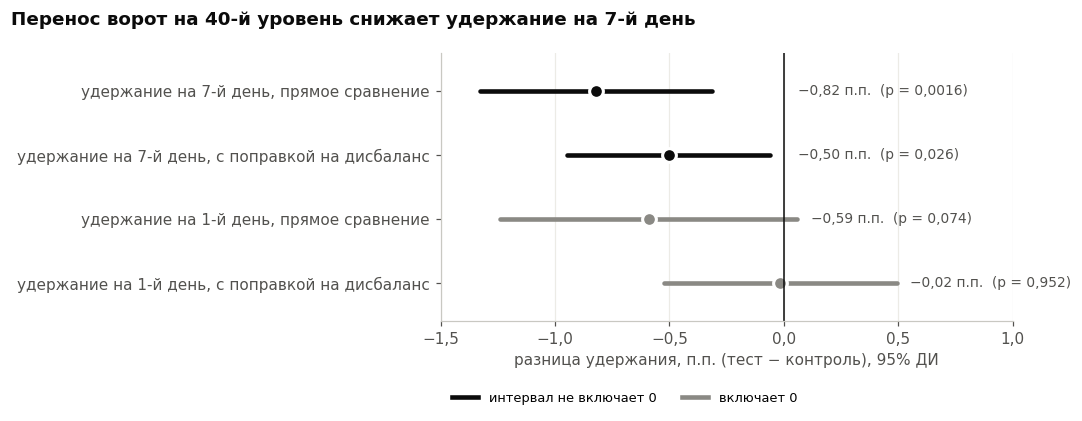

In [12]:
items = [("удержание на 7-й день, прямое сравнение", z["retention_7"]),
         ("удержание на 7-й день, с поправкой на дисбаланс", adj["retention_7"]),
         ("удержание на 1-й день, прямое сравнение", z["retention_1"]),
         ("удержание на 1-й день, с поправкой на дисбаланс", adj["retention_1"])]
fig, ax = plt.subplots(figsize=(9.5, 4))
for i, (name, r) in enumerate(items):
    y = len(items) - 1 - i
    sig = r["ci"][1] < 0 or r["ci"][0] > 0
    color = TEXT if sig else NEUTRAL
    ax.plot([r["ci"][0] * 100, r["ci"][1] * 100], [y, y], color=color, lw=3, solid_capstyle="round")
    ax.plot(r["diff"] * 100, y, "o", color=color, ms=9, mec="white", mew=2)
    ax.text(max(r["ci"][1] * 100, 0) + 0.06, y, f"{pp(r['diff'])} п.п.  (p = {pval(r['p_value'])})",
            va="center", fontsize=9, color=MUTED)
ax.axvline(0, color=TEXT, lw=1)
ax.set_yticks(range(len(items)), [n for n, _ in items][::-1])
ax.set_ylim(-0.6, len(items) - 0.4); ax.set_xlim(-1.5, 1.0)
ax.grid(axis="y", visible=False)
ax.plot([], [], color=TEXT, lw=3, label="интервал не включает 0")
ax.plot([], [], color=NEUTRAL, lw=3, label="включает 0")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2, fontsize=8.5)
commas(ax)
ax.set(xlabel="разница удержания, п.п. (тест − контроль), 95% ДИ")
fig.suptitle("Перенос ворот на 40-й уровень снижает удержание на 7-й день", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=TEXT)
fig.tight_layout()

| Метрика | Результат |
|---|---|
| **удержание на 7-й день (цель)** | прямое сравнение **−0,82 п.п.**, 95% ДИ [−1,33; −0,31], p ≈ 0,0016; с поправкой на дисбаланс **−0,50 п.п.** [−0,95; −0,06], p ≈ 0,026 |
| удержание на 1-й день | −0,59 п.п., p ≈ 0,074 (после Холма ≈ 0,10); с поправкой −0,02 п.п. — различий нет |
| раунды (барьер) | различия в пределах шума |
| в игроках | от ~500 (с поправкой) до ~820 (прямое сравнение) удержанных на 7-й день игроков меньше на каждые 100 000 установок |

По заранее записанному правилу решения ворота на 40-й уровень не переносим: удержание на 7-й день значимо хуже и в прямом сравнении, и с поправкой, а признаков пользы нет ни по одной метрике. Вероятная величина эффекта — около −0,5 п.п.: прямое сравнение её завышает из-за дисбаланса групп. Скорректированный эффект ниже минимального детектируемого для этого теста (ноутбук 3), так что запаса по мощности нет, и точная величина известна грубо.